In [1]:
import pandas as pd              
import matplotlib.pyplot as plt  
import seaborn as sns            

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [3]:
print("Dimensiones del dataset:", df.shape)
print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas")

Dimensiones del dataset: (6234, 12)
El dataset tiene 6234 filas y 12 columnas


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       6234 non-null   int64 
 1   type          6234 non-null   object
 2   title         6234 non-null   object
 3   director      4265 non-null   object
 4   cast          5664 non-null   object
 5   country       5758 non-null   object
 6   date_added    6223 non-null   object
 7   release_year  6234 non-null   int64 
 8   rating        6224 non-null   object
 9   duration      6234 non-null   object
 10  listed_in     6234 non-null   object
 11  description   6234 non-null   object
dtypes: int64(2), object(10)
memory usage: 584.6+ KB


In [5]:
print("--- VALORES NULOS POR COLUMNA ---")
print(df.isnull().sum())

print("\n--- PORCENTAJE DE NULOS ---")
print((df.isnull().sum() / len(df) * 100).round(2))

--- VALORES NULOS POR COLUMNA ---
show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64

--- PORCENTAJE DE NULOS ---
show_id          0.00
type             0.00
title            0.00
director        31.58
cast             9.14
country          7.64
date_added       0.18
release_year     0.00
rating           0.16
duration         0.00
listed_in        0.00
description      0.00
dtype: float64


In [6]:
duplicados = df.duplicated().sum()
print(f"Filas duplicadas: {duplicados}")

duplicados_titulo = df['title'].duplicated().sum()
print(f"Títulos duplicados: {duplicados_titulo}")

Filas duplicadas: 0
Títulos duplicados: 62


In [7]:
df.describe()

,show_id,release_year
count,6.234000e+03,6234.00000
mean,7.670368e+07,2013.35932
std,1.094296e+07,8.81162
min,2.477470e+05,1925.00000
25%,8.003580e+07,2013.00000
50%,8.016337e+07,2016.00000
75%,8.024489e+07,2018.00000
max,8.123573e+07,2020.00000


In [8]:
df_limpio = df.copy()

df_limpio['director'] = df_limpio['director'].fillna('Desconocido')
df_limpio['cast'] = df_limpio['cast'].fillna('Desconocido')
df_limpio['country'] = df_limpio['country'].fillna('Desconocido')
df_limpio = df_limpio.dropna(subset=['date_added', 'rating'])

print("--- NULOS DESPUES DE LA LIMPIEZA ---")
print(df_limpio.isnull().sum())
print(f"\nDimensiones despues de limpiar: {df_limpio.shape}")

--- NULOS DESPUES DE LA LIMPIEZA ---
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Dimensiones despues de limpiar: (6214, 12)


In [9]:
df_limpio['date_added'] = pd.to_datetime(df_limpio['date_added'], errors='coerce')

print(df_limpio['date_added'].dtype)
print(df_limpio['date_added'].head())

datetime64[ns]
0   2019-09-09
1   2016-09-09
2   2018-09-08
3   2018-09-08
4   2017-09-08
Name: date_added, dtype: datetime64[ns]


In [10]:
df_limpio['type'] = df_limpio['type'].replace({
    'Movie': 'Película',
    'TV Show': 'Serie'
})

print(df_limpio['type'].value_counts())

type
Película    4257
Serie       1957
Name: count, dtype: int64


In [12]:
# crear columnas nuevas
df_limpio['year_added'] = df_limpio['date_added'].dt.year
df_limpio['month_added'] = df_limpio['date_added'].dt.month
df_limpio['duration_num'] = df_limpio['duration'].str.extract('(\d+)').astype(float)
df_limpio['duration_unit'] = df_limpio['duration'].str.extract('([a-zA-Z]+)')
df_limpio['main_country'] = df_limpio['country'].str.split(',').str[0].str.strip()
df_limpio['main_genre'] = df_limpio['listed_in'].str.split(',').str[0].str.strip()
df_limpio[['title', 'type', 'year_added', 'duration_num', 'duration_unit', 'main_country', 'main_genre']].head()

,title,type,year_added,duration_num,duration_unit,main_country,main_genre
0,Norm of the North: King Sized Adventure,Película,2019.0,90.0,min,United States,Children & Family Movies
1,Jandino: Whatever it Takes,Película,2016.0,94.0,min,United Kingdom,Stand-Up Comedy
2,Transformers Prime,Serie,2018.0,1.0,Season,United States,Kids' TV
3,Transformers: Robots in Disguise,Serie,2018.0,1.0,Season,United States,Kids' TV
4,#realityhigh,Película,2017.0,99.0,min,United States,Comedies


In [13]:
peliculas = df_limpio[df_limpio['type'] == 'Película'].copy()
series = df_limpio[df_limpio['type'] == 'Serie'].copy()

print(f"Total de películas: {len(peliculas)}")
print(f"Total de series: {len(series)}")

peliculas_recientes_us = df_limpio[
    (df_limpio['type'] == 'Película') &
    (df_limpio['main_country'] == 'United States') &
    (df_limpio['year_added'] >= 2018)
]
print(f"\nPelículas de EEUU añadidas desde 2018: {len(peliculas_recientes_us)}")
peliculas_recientes_us[['title', 'year_added', 'main_genre']].head()

Total de películas: 4257
Total de series: 1957

Películas de EEUU añadidas desde 2018: 1154


,title,year_added,main_genre
0,Norm of the North: King Sized Adventure,2019.0,Children & Family Movies
27,City of Joy,2018.0,Documentaries
31,Sierra Burgess Is A Loser,2018.0,Comedies
40,Hell and Back,2018.0,Action & Adventure
45,ATM,2018.0,Comedies


In [15]:
print("--- CANTIDAD POR TIPO ---")
print(df_limpio.groupby('type').size())

print("\n--- TOP 10 PAISES ---")
print(df_limpio.groupby('main_country').size().sort_values(ascending=False).head(10))

print("\n--- CONTENIDO AÑADIDO POR AÑO ---")
print(df_limpio.groupby('year_added').size())

print("\n--- DURACION PROMEDIO DE PELICULAS POR DeCADA ---")
peliculas_temp = df_limpio[df_limpio['type'] == 'Película'].copy()
peliculas_temp['decada'] = (peliculas_temp['release_year'] // 10) * 10
print(peliculas_temp.groupby('decada')['duration_num'].mean().round(1))

--- CANTIDAD POR TIPO ---
type
Película    4257
Serie       1957
dtype: int64

--- TOP 10 PAISES ---
main_country
United States     2293
India              808
United Kingdom     482
Desconocido        471
Canada             206
Japan              182
France             147
South Korea        146
Spain              139
Mexico              99
dtype: int64

--- CONTENIDO AÑADIDO POR AÑO ---
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       7
2013.0       9
2014.0      19
2015.0      72
2016.0     409
2017.0    1181
2018.0    1628
2019.0    2057
2020.0     174
dtype: int64

--- DURACION PROMEDIO DE PELICULAS POR DeCADA ---
decada
1940     54.4
1950    115.8
1960    146.3
1970    112.6
1980    110.3
1990    111.2
2000    112.0
2010     96.1
2020    103.5
Name: duration_num, dtype: float64


# PREGUNTA 1: ¿Qué proporción hay entre películas y series en Netflix?

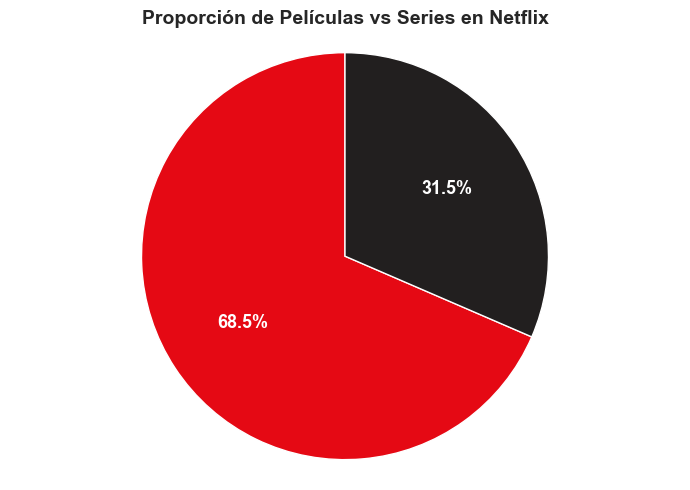

type
Película    4257
Serie       1957
Name: count, dtype: int64


In [18]:
conteo_tipo = df_limpio['type'].value_counts()

plt.figure(figsize=(7, 5))
colores = ['#E50914', '#221F1F']
plt.pie(conteo_tipo.values,
        labels=conteo_tipo.index,
        autopct='%1.1f%%',
        colors=colores,
        startangle=90,
        textprops={'fontsize': 13, 'color': 'white', 'fontweight': 'bold'})
plt.title('Proporción de Películas vs Series en Netflix', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.show()

print(conteo_tipo)

### Interpretación

Netflix ofrece aproximadamente el **doble de películas que de series** (68.5% vs 31.5%). Esto sugiere que, hasta 2020, la estrategia de la plataforma seguía inclinándose hacia el catálogo cinematográfico tradicional, aunque las series estaban ganando terreno con las producciones originales.

# PREGUNTA 2: ¿Cuáles son los 10 países que más contenido aportan?

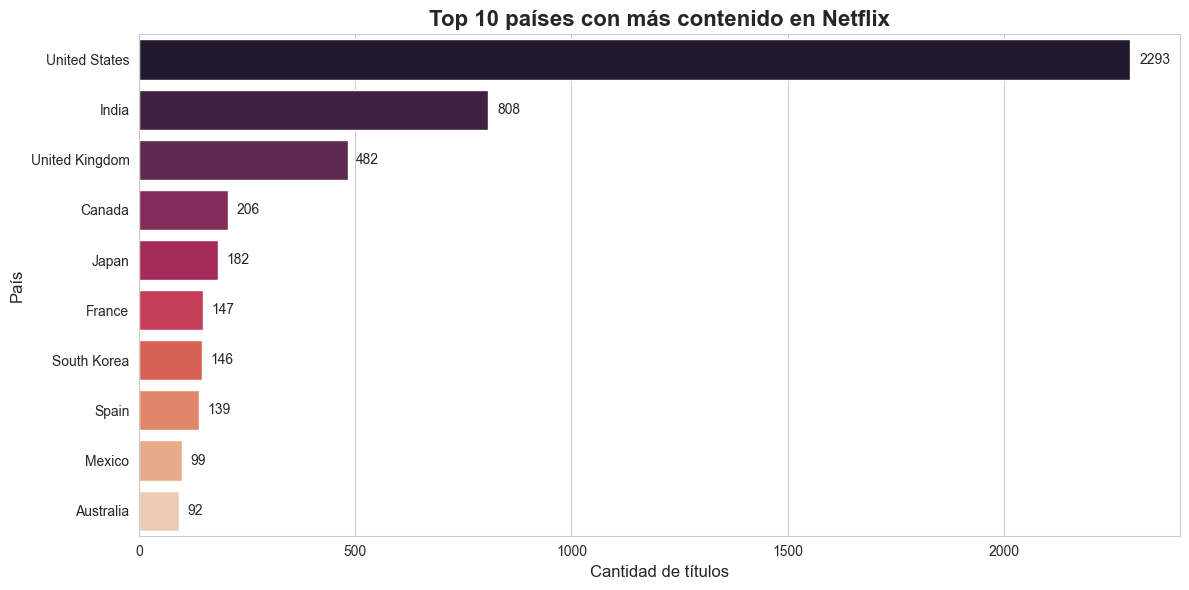

In [21]:
top_paises = df_limpio[df_limpio['main_country'] != 'Desconocido']
top_paises = top_paises['main_country'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_paises.values, y=top_paises.index,
            hue=top_paises.index, palette='rocket', legend=False)
plt.title('Top 10 países con más contenido en Netflix', fontsize=16, fontweight='bold')
plt.xlabel('Cantidad de títulos', fontsize=12)
plt.ylabel('País', fontsize=12)

for i, v in enumerate(top_paises.values):
    plt.text(v + 20, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Interpretación

**Estados Unidos domina de forma abrumadora** el catálogo de Netflix con más del doble de títulos que el segundo país. **India ocupa un sorprendente segundo lugar**, reflejando la enorme industria de Bollywood y la estrategia de Netflix por conquistar el mercado asiático. Reino Unido, Canadá y Francia completan el top 5, mostrando una fuerte presencia europea y norteamericana. Este dominio refleja el origen estadounidense de la plataforma y su expansión internacional gradual.

# PREGUNTA 3: ¿Cómo ha evolucionado el contenido añadido a Netflix por año?

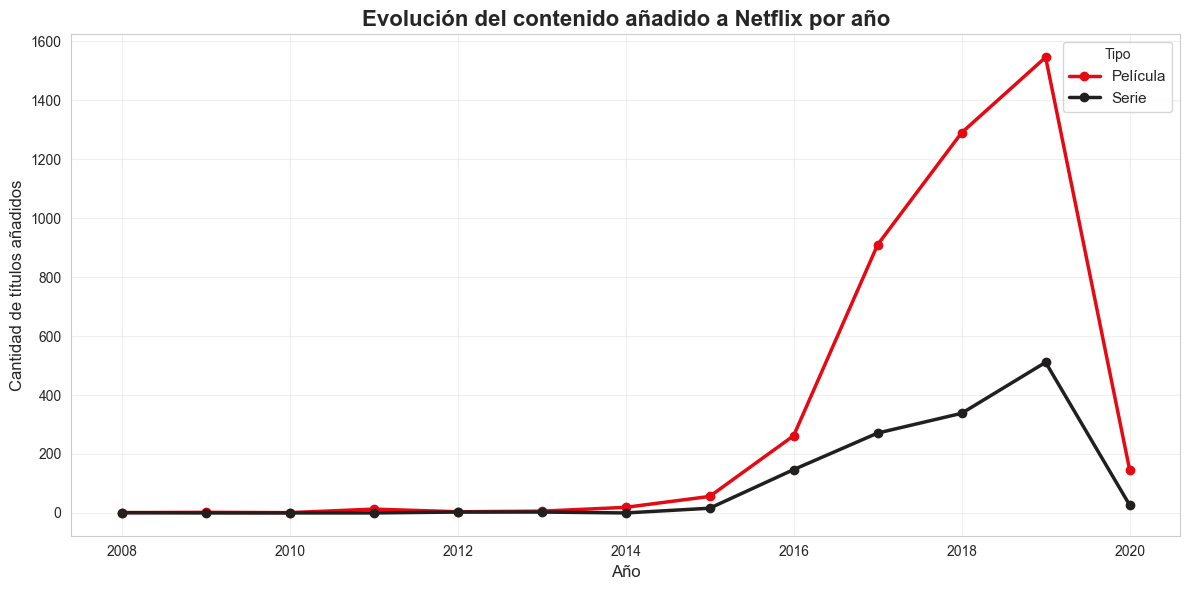

type        Película  Serie
year_added                 
2008.0             1      1
2009.0             2      0
2010.0             1      0
2011.0            13      0
2012.0             4      3
2013.0             6      3
2014.0            19      0
2015.0            56     16
2016.0           262    147
2017.0           910    271
2018.0          1290    338
2019.0          1546    511
2020.0           147     27


In [23]:
contenido_por_año = df_limpio.groupby(['year_added', 'type']).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
contenido_por_año.plot(kind='line', marker='o', linewidth=2.5,
                       color=['#E50914', '#221F1F'], ax=plt.gca())
plt.title('Evolución del contenido añadido a Netflix por año', fontsize=16, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Cantidad de títulos añadidos', fontsize=12)
plt.legend(title='Tipo', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(contenido_por_año)

### Interpretación

Netflix experimentó un **crecimiento explosivo** en la incorporación de contenido a partir de **2015**, alcanzando su pico en **2019**. Las películas siempre han superado a las series en cantidad de incorporaciones anuales, pero ambas curvas siguen el mismo patrón de crecimiento acelerado. Este comportamiento coincide con la expansión global de Netflix y su fuerte inversión en producciones originales durante ese período.

# PREGUNTA 4: ¿Cuáles son los géneros más comunes en Netflix?

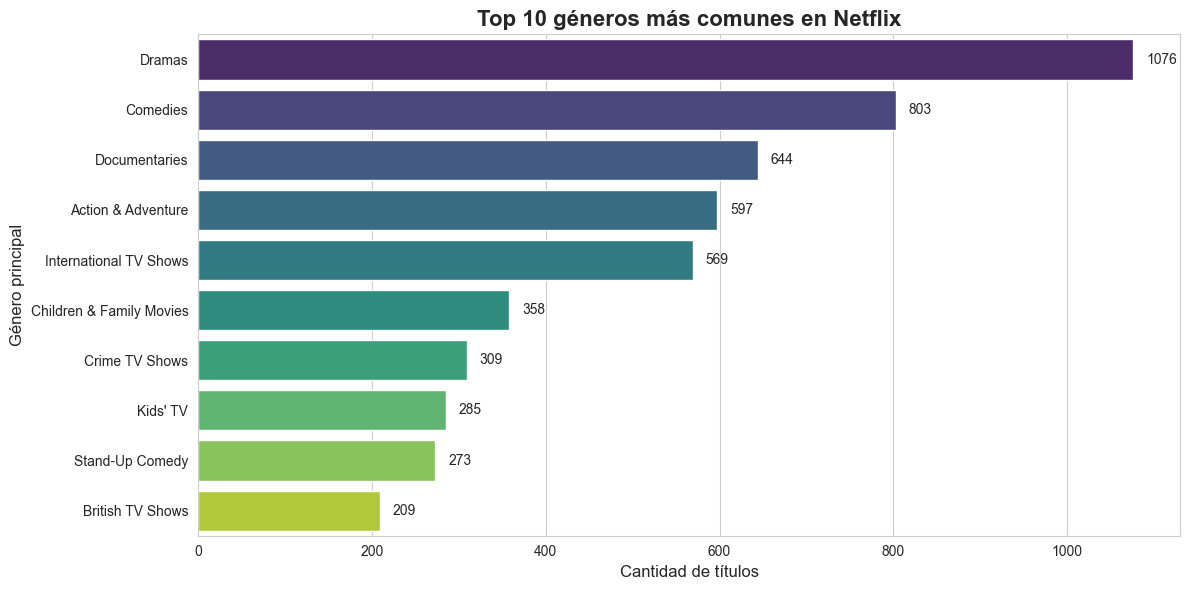

In [24]:
top_generos = df_limpio['main_genre'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_generos.values, y=top_generos.index,
            hue=top_generos.index, palette='viridis', legend=False)
plt.title('Top 10 géneros más comunes en Netflix', fontsize=16, fontweight='bold')
plt.xlabel('Cantidad de títulos', fontsize=12)
plt.ylabel('Género principal', fontsize=12)

for i, v in enumerate(top_generos.values):
    plt.text(v + 15, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Interpretación

Los **dramas** y las **comedias** dominan el catálogo de Netflix, seguidos por los **documentales**. Esto refleja las preferencias globales del público, que tiende a consumir historias emocionales y contenido de humor. La fuerte presencia de documentales evidencia la apuesta de Netflix por producir contenido de no-ficción, un segmento en el que se ha destacado con producciones originales muy premiadas.

# PREGUNTA 5: ¿Cuál es la duración promedio de las películas por década?

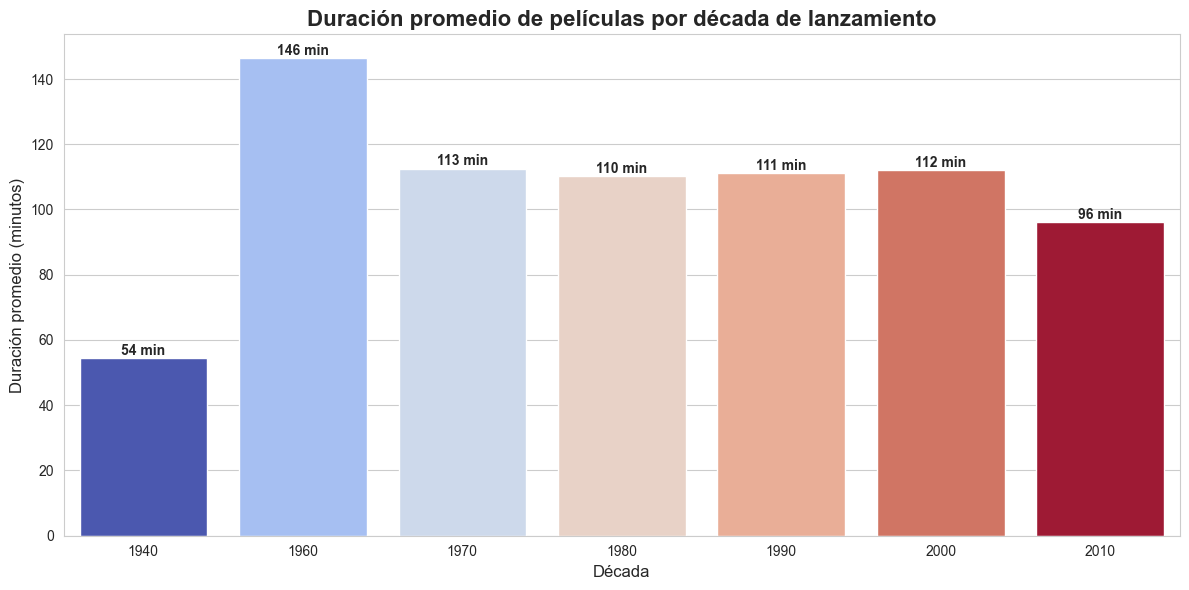

   decada  duracion_promedio  cantidad
0    1940          54.428571        14
2    1960         146.333333        18
3    1970         112.557692        52
4    1980         110.329268        82
5    1990         111.181818       165
6    2000         111.998047       512
7    2010          96.063786      3402


In [25]:
peliculas_dur = df_limpio[df_limpio['type'] == 'Película'].copy()
peliculas_dur['decada'] = (peliculas_dur['release_year'] // 10) * 10

duracion_por_decada = peliculas_dur.groupby('decada').agg(
    duracion_promedio=('duration_num', 'mean'),
    cantidad=('duration_num', 'count')
).reset_index()
duracion_por_decada = duracion_por_decada[duracion_por_decada['cantidad'] >= 10]

plt.figure(figsize=(12, 6))
sns.barplot(data=duracion_por_decada, x='decada', y='duracion_promedio',
            hue='decada', palette='coolwarm', legend=False)
plt.title('Duración promedio de películas por década de lanzamiento', fontsize=16, fontweight='bold')
plt.xlabel('Década', fontsize=12)
plt.ylabel('Duración promedio (minutos)', fontsize=12)

for i, row in enumerate(duracion_por_decada.itertuples()):
    plt.text(i, row.duracion_promedio + 1, f"{row.duracion_promedio:.0f} min",
             ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print(duracion_por_decada)

### Interpretación

Las películas más antiguas del catálogo (décadas de **1950-1970**) tienden a ser más largas, superando los **110 minutos** en promedio. A partir de los años 90, la duración se estabiliza alrededor de los **95-110 minutos**, reflejando un formato estándar de la industria moderna. Es notable la caída en la década de 2010, donde el promedio baja a ~96 minutos, coincidiendo con el auge de películas de streaming más compactas y directas.

# Conclusiones del Análisis

A partir del análisis realizado sobre el catálogo de Netflix (6.234 títulos hasta 2020), se pueden extraer las siguientes conclusiones relevantes:

## 1️. Netflix es predominantemente una plataforma de películas, pero con estrategia de expansión hacia series

Aunque el catálogo se compone en un **68.5% de películas y 31.5% de series**, la evolución anual muestra que las series han crecido a un ritmo similar al de las películas desde 2015. Esto sugiere que Netflix inicialmente construyó su catálogo con licencias cinematográficas, pero está invirtiendo fuertemente en producción propia de series originales para diferenciarse de la competencia. La estrategia responde a un cambio en los hábitos de consumo: los usuarios modernos prefieren narrativas largas y episódicas que fidelicen su suscripción mes a mes.

## 2️. Existe una fuerte concentración geográfica angloamericana, pero India rompe el patrón

**Estados Unidos aporta el 36% del catálogo (2.293 títulos)**, más del doble que el segundo país. Sin embargo, la presencia de **India en segundo lugar con 808 títulos** es un hallazgo significativo: revela que Netflix no solo replica contenido occidental, sino que apuesta agresivamente por mercados emergentes con industrias cinematográficas robustas (Bollywood). Esta diversificación es clave para la estrategia global de la plataforma, especialmente considerando que mercados como India o Corea del Sur (con 146 títulos y crecimiento acelerado) representan cientos de millones de suscriptores potenciales.

## 3️. La duración de las películas ha disminuido en la era del streaming

El análisis por décadas muestra una **caída notable en la duración promedio: de ~112 minutos en las décadas 1980-2000 a apenas 96 minutos en la década 2010**. Este patrón coincide con el auge del streaming y refleja un cambio en el comportamiento del espectador: la atención se ha fragmentado, y las plataformas priorizan contenido más directo y consumible en una sola sesión. Además, la década 2010 concentra el 82% de las películas del catálogo (3.402 títulos), evidenciando que Netflix se enfoca en producción y adquisición reciente, no en un catálogo histórico completo.